In [6]:
from google.colab import drive
drive.mount('/content/drive')

import os
path = '/content/drive/MyDrive/cleaned_full_data.parquet'
print(os.path.getsize(path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
280725379


In [7]:
import pandas as pd
df = pd.read_parquet(path)
print(df.shape)

# departures only = taxi-out
dep = df[df['PHASE_mvt'] == 'DEP'].copy()

# drop the few invalid taxi times
dep = dep[dep['taxi_time_valid'] & ~dep['taxi_time_outlier']]

# time features from off-block time
dep['hour'] = dep['BLOCK_TIME_UTC_mvt'].dt.hour
dep['dayofweek'] = dep['BLOCK_TIME_UTC_mvt'].dt.dayofweek
dep['month'] = dep['BLOCK_TIME_UTC_mvt'].dt.month
dep['delay_min'] = (dep['BLOCK_TIME_UTC_mvt'] - dep['SCHED_TIME_UTC_mvt']).dt.total_seconds() / 60

cat_features = ['ADEP_mvt', 'RUNWAY_mvt', 'STAND_mvt', 'AIRCRAFT_TYPE_mvt',
                'WK_TBL_CAT_flt', 'AIRCRAFT_OPERATOR_flt', 'MARKET_SEGMENT_flt', 'ADES_mvt']
num_features = ['hour', 'dayofweek', 'month', 'delay_min']

for c in cat_features:
    dep[c] = dep[c].astype('category')

X = dep[cat_features + num_features]
y = dep['TAXITIME_SEC_mvt']
print(X.shape)
print(y.describe())

(4167797, 33)
(2084625, 12)
count    2.084625e+06
mean     9.902647e+02
std      4.626796e+02
min      1.000000e+00
25%      7.190000e+02
50%      9.120000e+02
75%      1.188000e+03
max      4.266100e+04
Name: TAXITIME_SEC_mvt, dtype: float64


Notes:

2.08M departures

median taxi-out of 912 s (about 15 min)

mean of 990 s

!!

1-second taxi can't happen

maximum of 42,661 s is almost 12 hours

Keeping only taxi times between 1 minute and 2 hours

In [8]:
dep = dep[dep['TAXITIME_SEC_mvt'].between(60, 7200)]
X = dep[cat_features + num_features]
y = dep['TAXITIME_SEC_mvt']
print(len(dep))

2083358


In [9]:
t = dep['BLOCK_TIME_UTC_mvt']
train_mask = t <  '2025-11-01'
valid_mask = (t >= '2025-11-01') & (t < '2025-12-01')
test_mask  = t >= '2025-12-01'

X_train, y_train = X[train_mask], y[train_mask]
X_valid, y_valid = X[valid_mask], y[valid_mask]
X_test,  y_test  = X[test_mask],  y[test_mask]

print(len(X_train), len(X_valid), len(X_test))

1755536 162258 165564


In [10]:
import numpy as np
import xgboost as xgb

def rmse(a, b):
    return np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2))

# median taxi-out per airport + runway, learned on train only
key_train = X_train['ADEP_mvt'].astype(str) + '_' + X_train['RUNWAY_mvt'].astype(str)
key_valid = X_valid['ADEP_mvt'].astype(str) + '_' + X_valid['RUNWAY_mvt'].astype(str)
medians = y_train.groupby(key_train).median()
baseline_pred = key_valid.map(medians).fillna(y_train.median())
print('Baseline RMSE (valid):', round(rmse(y_valid, baseline_pred), 1))

model = xgb.XGBRegressor(
    n_estimators=3000,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    enable_categorical=True,   # uses the category columns directly
    max_cat_to_onehot=1,
    eval_metric='rmse',
    early_stopping_rounds=100, # stop when validation RMSE stops improving
    random_state=42,           # reproducibility
    device='cuda',
)

model.fit(X_train, y_train,
          eval_set=[(X_valid, y_valid)],
          verbose=200)

print('Best iteration:', model.best_iteration)
print('XGBoost RMSE (valid):', round(rmse(y_valid, model.predict(X_valid)), 1))

Baseline RMSE (valid): 364.3


/usr/local/lib/python3.13/dist-packages/xgboost/callback.py:385: UserWarning: [15:25:09] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  self.starting_round = model.num_boosted_rounds()
/usr/local/lib/python3.13/dist-packages/xgboost/callback.py:385: UserWarning: [15:25:09] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  self.starting_round = model.num_boosted_rounds()


[0]	validation_0-rmse:404.50322
[200]	validation_0-rmse:310.08144
[400]	validation_0-rmse:309.13710
[600]	validation_0-rmse:309.09689
[607]	validation_0-rmse:309.11057
Best iteration: 507
XGBoost RMSE (valid): 309.0


Notes:

XGBoost got 309.0 s on the validation month, against 364.3 s for the baseline.

55 seconds, or 15%, better

In [11]:
import pandas as pd

test_pred = model.predict(X_test)
print('XGBoost RMSE (test):', round(rmse(y_test, test_pred), 1))

# baseline on test: for comparison
key_test = X_test['ADEP_mvt'].astype(str) + '_' + X_test['RUNWAY_mvt'].astype(str)
baseline_test = key_test.map(medians).fillna(y_train.median())
print('Baseline RMSE (test):', round(rmse(y_test, baseline_test), 1))

# RMSE per airport
per_airport = (pd.DataFrame({'airport': X_test['ADEP_mvt'], 'err2': (y_test - test_pred) ** 2})
               .groupby('airport', observed=True)['err2'].mean() ** 0.5)
print(per_airport.round(1).sort_values())

# which features the model uses most
imp = pd.Series(model.get_booster().get_score(importance_type='gain'))
print((imp / imp.sum()).sort_values(ascending=False).round(3))

XGBoost RMSE (test): 315.6
Baseline RMSE (test): 373.4
airport
EHAM    212.7
LEMD    224.3
LEBL    241.0
EDDF    256.2
LSZH    256.8
LTFM    320.6
LFPG    366.7
EGLL    367.1
LIRF    417.3
EDDM    436.9
Name: err2, dtype: float64
WK_TBL_CAT_flt           0.369
ADEP_mvt                 0.267
RUNWAY_mvt               0.107
STAND_mvt                0.054
AIRCRAFT_OPERATOR_flt    0.051
MARKET_SEGMENT_flt       0.044
AIRCRAFT_TYPE_mvt        0.027
hour                     0.025
ADES_mvt                 0.023
month                    0.015
delay_min                0.014
dayofweek                0.006
dtype: float64


Notes:

XGBoost got 315.6 s on December against 373.4 s for the baseline

15% better again

no sign of leakage:

why - close to the 309 s it got on November

model is learning real patterns rather than memorising the training months

Per airport:

Amsterdam and Madrid are already good, at about 3.5 minutes of error

Munich, Rome, Heathrow and Paris CDG are the problem airports, at 6–7 minutes.

Munich:  December maybe de-icing is a likely culprit and that's a weather effect the model can't see yet

Rome: the current features don't suggest a clear reason

Heathrow and CDG are congested airports: the model has nothing yet that tells it how busy the airport is at that moment

! Feature importance

Wake category is ranked first: maybe because heavy long-haul aircraft that taxi to particular runways

Important!

The time features (hour, day of week, month) and delay are near the bottom. The model knows when a flight leaves, but not how busy the airport is at that moment

In [12]:
import numpy as np

def to_sec(s):
    return (s - pd.Timestamp('1970-01-01', tz='UTC')).dt.total_seconds().to_numpy()

dep = dep.sort_values('BLOCK_TIME_UTC_mvt')
arr = df[df['PHASE_mvt'] == 'ARR']

for ap, g in dep.groupby('ADEP_mvt', observed=True):
    t = to_sec(g['BLOCK_TIME_UTC_mvt'])
    landings = np.sort(to_sec(arr.loc[arr['ADES_mvt'] == ap, 'MVT_TIME_UTC_mvt']))

    for w in [15, 30, 60]:
        # other pushbacks in [t - w, t)
        dep.loc[g.index, f'push_prev_{w}m'] = (np.searchsorted(t, t, 'left')
                                               - np.searchsorted(t, t - w * 60, 'left'))
    # arrivals landed in [t - 30, t)
    dep.loc[g.index, 'arr_prev_30m'] = (np.searchsorted(landings, t, 'left')
                                        - np.searchsorted(landings, t - 30 * 60, 'left'))

num_features = ['hour', 'dayofweek', 'month', 'delay_min',
                'push_prev_15m', 'push_prev_30m', 'push_prev_60m', 'arr_prev_30m']
X = dep[cat_features + num_features]
y = dep['TAXITIME_SEC_mvt']
print(dep[['push_prev_15m', 'push_prev_30m', 'push_prev_60m', 'arr_prev_30m']].describe().round(1))

       push_prev_15m  push_prev_30m  push_prev_60m  arr_prev_30m
count      2083358.0      2083358.0      2083358.0     2083358.0
mean             8.9           17.8           34.5          15.3
std              4.2            7.5           13.4           6.9
min              0.0            0.0            0.0           0.0
25%              6.0           12.0           25.0          11.0
50%              9.0           18.0           35.0          15.0
75%             12.0           23.0           44.0          20.0
max             31.0           49.0           84.0          46.0


Notes:

The median is 9 pushbacks in 15 minutes, 18 in 30 and 35 in 60
35 departures an hour

busiest hour reaches 84 pushbacks

15 arrivals every 30 minutes or 30 an hour



!! Important - running the model with 16 features instead of original 12


In [13]:
t = dep['BLOCK_TIME_UTC_mvt']
train_mask = t <  '2025-11-01'
valid_mask = (t >= '2025-11-01') & (t < '2025-12-01')
test_mask  = t >= '2025-12-01'

X_train, y_train = X[train_mask], y[train_mask]
X_valid, y_valid = X[valid_mask], y[valid_mask]
X_test,  y_test  = X[test_mask],  y[test_mask]

print(len(X_train), len(X_valid), len(X_test))

1755536 162258 165564


In [14]:
import numpy as np
import xgboost as xgb

def rmse(a, b):
    return np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2))

# median taxi-out per airport + runway, learned on train only
key_train = X_train['ADEP_mvt'].astype(str) + '_' + X_train['RUNWAY_mvt'].astype(str)
key_valid = X_valid['ADEP_mvt'].astype(str) + '_' + X_valid['RUNWAY_mvt'].astype(str)
medians = y_train.groupby(key_train).median()
baseline_pred = key_valid.map(medians).fillna(y_train.median())
print('Baseline RMSE (valid):', round(rmse(y_valid, baseline_pred), 1))

model = xgb.XGBRegressor(
    n_estimators=3000,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    enable_categorical=True,
    max_cat_to_onehot=1,
    eval_metric='rmse',
    early_stopping_rounds=100,
    random_state=42,
    device='cuda',
)

model.fit(X_train, y_train,
          eval_set=[(X_valid, y_valid)],
          verbose=200)

print('Best iteration:', model.best_iteration)
print('XGBoost RMSE (valid):', round(rmse(y_valid, model.predict(X_valid)), 1))

Baseline RMSE (valid): 364.3


/usr/local/lib/python3.13/dist-packages/xgboost/callback.py:385: UserWarning: [15:47:54] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  self.starting_round = model.num_boosted_rounds()
/usr/local/lib/python3.13/dist-packages/xgboost/callback.py:385: UserWarning: [15:47:54] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  self.starting_round = model.num_boosted_rounds()


[0]	validation_0-rmse:404.43017
[200]	validation_0-rmse:304.11750
[400]	validation_0-rmse:302.66606
[600]	validation_0-rmse:302.26711
[769]	validation_0-rmse:302.32187
Best iteration: 669
XGBoost RMSE (valid): 302.2


Notes:

congestion features helped but only a little

RMSE went from 309.0 s to 302.2 s which means about 7 seconds or 2% better

model also kept improving for longer this time

best iteration 669 instead of 507

it found the new columns useful, but only a little

what i think:

the counts cover the whole airport , but a taxiing flight only really queues behind traffic going to its own runway.

at big airprots like Heatrhow or CDG 5 pushbacks an hour spread across several runways doesn't tell the model much about any one queue



options that i though about:

1. Make runway and stand airport-specific.

2. Count congestion per runway instead of per airport.

In [15]:
# give each airport its own runway and stand names
dep['RUNWAY_mvt'] = (dep['ADEP_mvt'].astype(str) + '_' + dep['RUNWAY_mvt'].astype(str)).astype('category')
dep['STAND_mvt']  = (dep['ADEP_mvt'].astype(str) + '_' + dep['STAND_mvt'].astype(str)).astype('category')

X = dep[cat_features + num_features]
y = dep['TAXITIME_SEC_mvt']
print(X['RUNWAY_mvt'].nunique(), 'runways |', X['STAND_mvt'].nunique(), 'stands')
print(X['RUNWAY_mvt'].head())

70 runways | 2719 stands
258571    LTFM_35L
258567    LTFM_35L
258572    LTFM_35L
258573     LTFM_36
148621    LEMD_36L
Name: RUNWAY_mvt, dtype: category
Categories (70, object): ['EDDF_07C', 'EDDF_07R', 'EDDF_18', 'EDDF_25C', ..., 'LTFM_34R', 'LTFM_35L',
                          'LTFM_35R', 'LTFM_36']


re-running it again

In [16]:
t = dep['BLOCK_TIME_UTC_mvt']
train_mask = t <  '2025-11-01'
valid_mask = (t >= '2025-11-01') & (t < '2025-12-01')
test_mask  = t >= '2025-12-01'

X_train, y_train = X[train_mask], y[train_mask]
X_valid, y_valid = X[valid_mask], y[valid_mask]
X_test,  y_test  = X[test_mask],  y[test_mask]

print(len(X_train), len(X_valid), len(X_test))

1755536 162258 165564


In [17]:
import numpy as np
import xgboost as xgb

def rmse(a, b):
    return np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2))

# median taxi-out per airport + runway
key_train = X_train['ADEP_mvt'].astype(str) + '_' + X_train['RUNWAY_mvt'].astype(str)
key_valid = X_valid['ADEP_mvt'].astype(str) + '_' + X_valid['RUNWAY_mvt'].astype(str)
medians = y_train.groupby(key_train).median()
baseline_pred = key_valid.map(medians).fillna(y_train.median())
print('Baseline RMSE (valid):', round(rmse(y_valid, baseline_pred), 1))

model = xgb.XGBRegressor(
    n_estimators=3000,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    enable_categorical=True,
    max_cat_to_onehot=1,
    eval_metric='rmse',
    early_stopping_rounds=100,
    random_state=42,
    device='cuda',
)

model.fit(X_train, y_train,
          eval_set=[(X_valid, y_valid)],
          verbose=200)

print('Best iteration:', model.best_iteration)
print('XGBoost RMSE (valid):', round(rmse(y_valid, model.predict(X_valid)), 1))

Baseline RMSE (valid): 364.3


/usr/local/lib/python3.13/dist-packages/xgboost/callback.py:385: UserWarning: [16:08:46] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  self.starting_round = model.num_boosted_rounds()
/usr/local/lib/python3.13/dist-packages/xgboost/callback.py:385: UserWarning: [16:08:46] WARNING: /__w/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  self.starting_round = model.num_boosted_rounds()


[0]	validation_0-rmse:404.38815
[200]	validation_0-rmse:303.99859
[400]	validation_0-rmse:302.41674
[600]	validation_0-rmse:301.85675
[772]	validation_0-rmse:301.72315
Best iteration: 672
XGBoost RMSE (valid): 301.7


Notes:

RMSE barely moved, from 302.2 s to 301.7 s, only half a second

the model had mostly been combining airport and runway on its own already which i wanted to double check



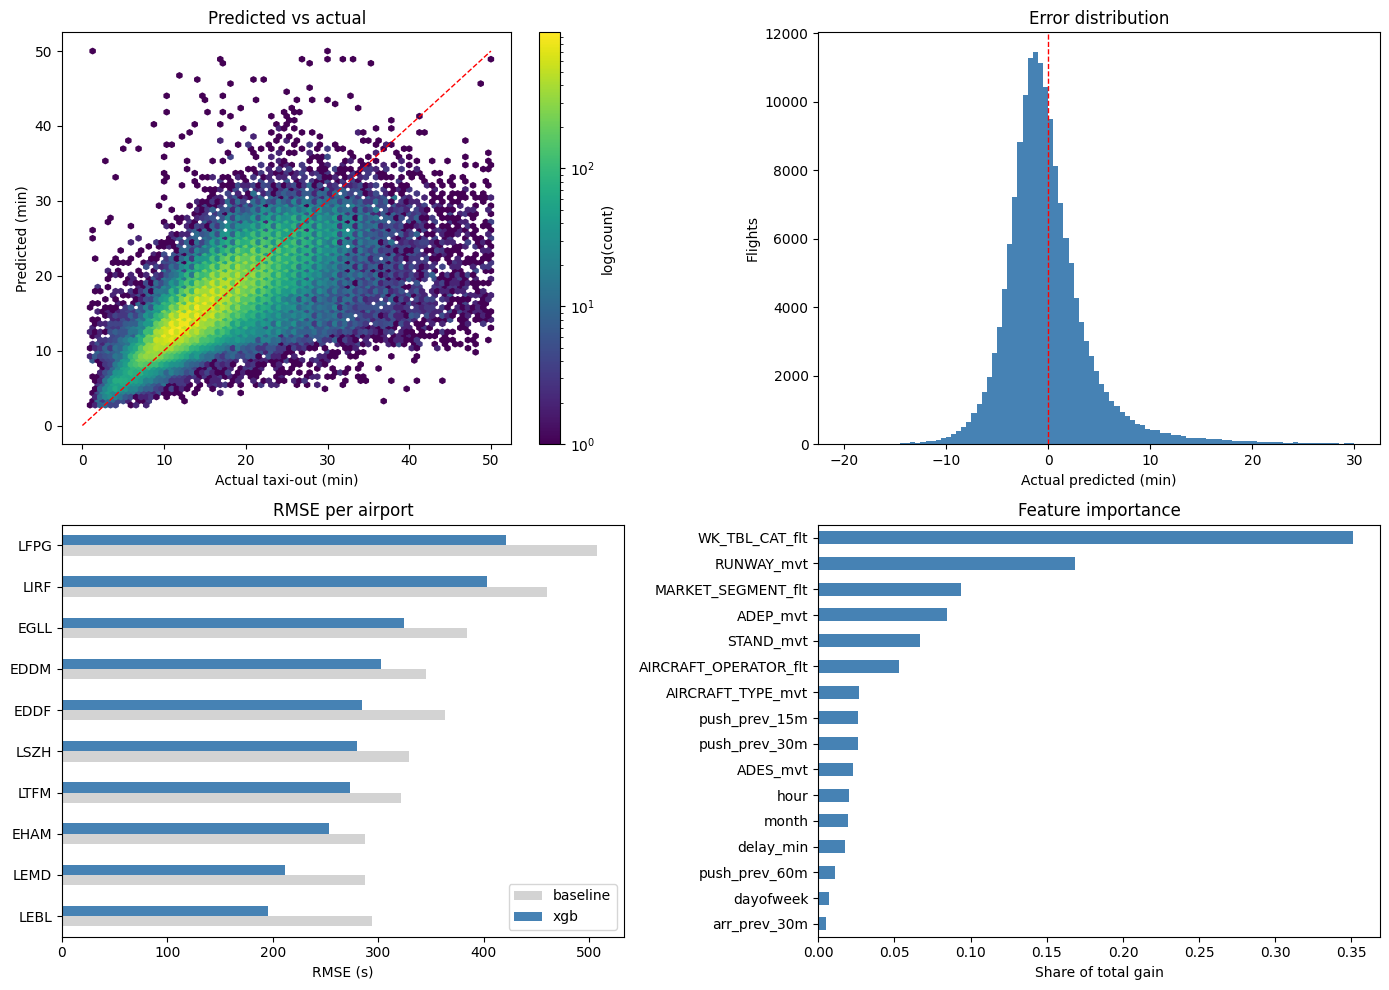

In [19]:
import matplotlib.pyplot as plt

valid_pred = model.predict(X_valid)
resid = y_valid - valid_pred

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Predicted vs actual
ax = axes[0, 0]
hb = ax.hexbin(y_valid / 60, valid_pred / 60, gridsize=80, bins='log', cmap='viridis',
               extent=(0, 50, 0, 50))
ax.plot([0, 50], [0, 50], 'r--', lw=1)
ax.set(xlabel='Actual taxi-out (min)', ylabel='Predicted (min)', title='Predicted vs actual')
fig.colorbar(hb, ax=ax, label='log(count)')

# Error distribution
ax = axes[0, 1]
ax.hist(resid / 60, bins=100, range=(-20, 30), color='steelblue')
ax.axvline(0, color='r', ls='--', lw=1)
ax.set(xlabel='Actual predicted (min)', ylabel='Flights', title='Error distribution')

# RMSE per airport: baseline vs XGBoost
ax = axes[1, 0]
per_ap = pd.DataFrame({
    'airport': X_valid['ADEP_mvt'].astype(str),
    'xgb': (y_valid - valid_pred) ** 2,
    'baseline': (y_valid - baseline_pred) ** 2,
}).groupby('airport')[['baseline', 'xgb']].mean() ** 0.5
per_ap.sort_values('xgb').plot.barh(ax=ax, color=['lightgray', 'steelblue'])
ax.set(xlabel='RMSE (s)', ylabel='', title='RMSE per airport')

# Feature importance
ax = axes[1, 1]
imp = pd.Series(model.get_booster().get_score(importance_type='gain'))
(imp / imp.sum()).sort_values().plot.barh(ax=ax, color='steelblue')
ax.set(xlabel='Share of total gain', title='Feature importance')

plt.tight_layout()
plt.show()

Tuning the model next

In [20]:
!pip install -q optuna
import optuna

# smaller sample for faster tuning
Xs = X_train.sample(400_000, random_state=42)
ys = y_train.loc[Xs.index]

def objective(trial):
    params = {
        'max_depth':        trial.suggest_int('max_depth', 4, 12),
        'min_child_weight': trial.suggest_float('min_child_weight', 1, 100, log=True),
        'subsample':        trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_lambda':       trial.suggest_float('reg_lambda', 0.1, 50, log=True),
    }
    m = xgb.XGBRegressor(
        n_estimators=2000, learning_rate=0.1,
        tree_method='hist', enable_categorical=True, max_cat_to_onehot=1,
        eval_metric='rmse', early_stopping_rounds=50,
        random_state=42, n_jobs=-1, **params)
    m.fit(Xs, ys, eval_set=[(X_valid, y_valid)], verbose=False)
    return rmse(y_valid, m.predict(X_valid))

study = optuna.create_study(direction='minimize',
                            sampler=optuna.samplers.TPESampler(seed=42))
# trial 0 = your current settings, as a reference point
study.enqueue_trial({'max_depth': 8, 'min_child_weight': 1, 'subsample': 0.8,
                     'colsample_bytree': 0.8, 'reg_lambda': 1})
study.optimize(objective, n_trials=10, show_progress_bar=True)

print('Current settings RMSE:', round(study.trials[0].value, 1))
print('Best RMSE:', round(study.best_value, 1))
print('Best settings:', study.best_params)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 21.5 MB/s eta 0:00:00


[I 2026-09-23 16:27:57,726] A new study created in memory with name: no-name-b45eb8af-a145-45bc-ae82-abae255b39a2


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-09-23 16:29:27,139] Trial 0 finished with value: 310.3426478597902 and parameters: {'max_depth': 8, 'min_child_weight': 1, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 1}. Best is trial 0 with value: 310.3426478597902.
[I 2026-09-23 16:30:39,249] Trial 1 finished with value: 310.0224434818388 and parameters: {'max_depth': 7, 'min_child_weight': 79.69454818643933, 'subsample': 0.892797576724562, 'colsample_bytree': 0.7993292420985183, 'reg_lambda': 0.26368755339723043}. Best is trial 1 with value: 310.0224434818388.
[I 2026-09-23 16:32:00,990] Trial 2 finished with value: 310.68089461937865 and parameters: {'max_depth': 5, 'min_child_weight': 1.3066739238053278, 'subsample': 0.9464704583099741, 'colsample_bytree': 0.8005575058716043, 'reg_lambda': 8.148293210105287}. Best is trial 1 with value: 310.0224434818388.
[I 2026-09-23 16:35:03,115] Trial 3 finished with value: 309.7071687497106 and parameters: {'max_depth': 4, 'min_child_weight': 87.06020878304857, 'subsampl

Notes:

trial 5 scored 308.3 s, against 310.3 s

2-second gap on a 400K-row sample could partly be noise

original settings were already close to the best

worst trials also point somewhere useful: trial 7 and small row samples (around 61–64%) hurt the score

the remaining gains are more likely to come from features than from settings



In [21]:
best = study.best_params

model_tuned = xgb.XGBRegressor(
    n_estimators=3000, learning_rate=0.05,
    tree_method='hist', enable_categorical=True, max_cat_to_onehot=1,
    eval_metric='rmse', early_stopping_rounds=100,
    random_state=42, n_jobs=-1, **best)

model_tuned.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=200)

print('Best iteration:', model_tuned.best_iteration)
print('Tuned RMSE (valid):', round(rmse(y_valid, model_tuned.predict(X_valid)), 1), '| before: 301.7')

[0]	validation_0-rmse:404.19004
[200]	validation_0-rmse:302.29751
[400]	validation_0-rmse:300.89265
[600]	validation_0-rmse:300.54222
[754]	validation_0-rmse:300.49308
Best iteration: 654
Tuned RMSE (valid): 300.5 | before: 301.7


tuned model scored 300.5 s, about 1.2 seconds better than 301.7 s



In [22]:
# tuned settings
use_tuned = True
params = study.best_params if use_tuned else dict(
    max_depth=8, min_child_weight=1, subsample=0.8, colsample_bytree=0.8, reg_lambda=1)

# per-runway congestion
for rwy, g in dep.groupby('RUNWAY_mvt', observed=True):
    t = to_sec(g['BLOCK_TIME_UTC_mvt'])
    ev = np.sort(t)
    for w in [15, 30]:
        dep.loc[g.index, f'rwy_push_prev_{w}m'] = (np.searchsorted(ev, t, 'left')
                                                   - np.searchsorted(ev, t - w * 60, 'left'))

num_features = ['hour', 'dayofweek', 'month', 'delay_min',
                'push_prev_15m', 'push_prev_30m', 'push_prev_60m', 'arr_prev_30m',
                'rwy_push_prev_15m', 'rwy_push_prev_30m']
X = dep[cat_features + num_features]
y = dep['TAXITIME_SEC_mvt']

# split again (same dates as before)
t = dep['BLOCK_TIME_UTC_mvt']
train_mask = t < '2025-11-01'
valid_mask = (t >= '2025-11-01') & (t < '2025-12-01')
test_mask  = t >= '2025-12-01'
X_train, y_train = X[train_mask], y[train_mask]
X_valid, y_valid = X[valid_mask], y[valid_mask]
X_test,  y_test  = X[test_mask],  y[test_mask]
print(X_train.shape)

# should now have 18 columns

# retrain
model = xgb.XGBRegressor(
    n_estimators=3000, learning_rate=0.05,
    tree_method='hist', enable_categorical=True, max_cat_to_onehot=1,
    eval_metric='rmse', early_stopping_rounds=100,
    random_state=42, n_jobs=-1, **params)
model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=200)

print('Best iteration:', model.best_iteration)
print('RMSE (valid):', round(rmse(y_valid, model.predict(X_valid)), 1), '| to beat: 300.5')

(1755536, 18)
[0]	validation_0-rmse:404.40522
[200]	validation_0-rmse:300.88676
[400]	validation_0-rmse:299.47205
[600]	validation_0-rmse:299.07197
[691]	validation_0-rmse:299.12926
Best iteration: 591
RMSE (valid): 299.1 | to beat: 300.5


!! Important

Step	Valid RMSE (in seconds)
Baseline (median per airport-runway)	364.3
First XGBoost	309.0
+ airport-wide congestion	302.2
+ airport-specific runway/stand	301.7
+ tuned settings	300.5
+ per-runway congestion	299.1

adding charts

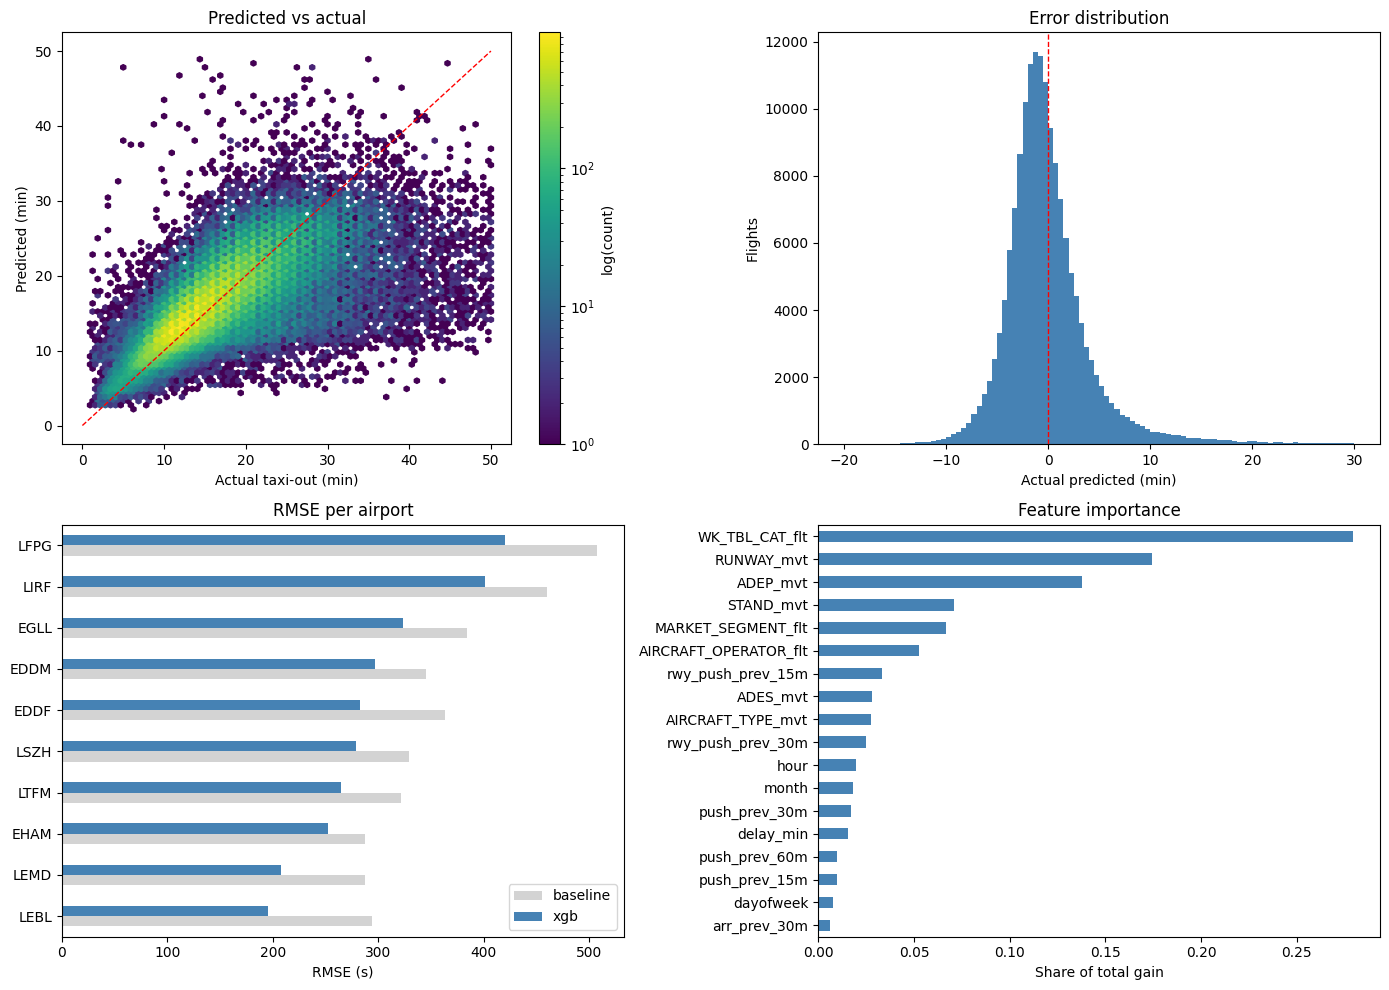

In [23]:
import matplotlib.pyplot as plt

valid_pred = model.predict(X_valid)
resid = y_valid - valid_pred

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# predicted vs actual
ax = axes[0, 0]
hb = ax.hexbin(y_valid / 60, valid_pred / 60, gridsize=80, bins='log', cmap='viridis',
               extent=(0, 50, 0, 50))
ax.plot([0, 50], [0, 50], 'r--', lw=1)
ax.set(xlabel='Actual taxi-out (min)', ylabel='Predicted (min)', title='Predicted vs actual')
fig.colorbar(hb, ax=ax, label='log(count)')

# error distribution
ax = axes[0, 1]
ax.hist(resid / 60, bins=100, range=(-20, 30), color='steelblue')
ax.axvline(0, color='r', ls='--', lw=1)
ax.set(xlabel='Actual predicted (min)', ylabel='Flights', title='Error distribution')

# RMSE per airport: baseline vs XGBoost
ax = axes[1, 0]
per_ap = pd.DataFrame({
    'airport': X_valid['ADEP_mvt'].astype(str),
    'xgb': (y_valid - valid_pred) ** 2,
    'baseline': (y_valid - baseline_pred) ** 2,
}).groupby('airport')[['baseline', 'xgb']].mean() ** 0.5
per_ap.sort_values('xgb').plot.barh(ax=ax, color=['lightgray', 'steelblue'])
ax.set(xlabel='RMSE (s)', ylabel='', title='RMSE per airport')

# feature importance
ax = axes[1, 1]
imp = pd.Series(model.get_booster().get_score(importance_type='gain'))
(imp / imp.sum()).sort_values().plot.barh(ax=ax, color='steelblue')
ax.set(xlabel='Share of total gain', title='Feature importance')

plt.tight_layout()
plt.show()

In [24]:
# December test
test_pred = model.predict(X_test)
print('XGBoost RMSE (test):', round(rmse(y_test, test_pred), 1), '| first model: 315.6 | baseline: 373.4')

per_airport = (pd.DataFrame({'airport': X_test['ADEP_mvt'].astype(str), 'err2': (y_test - test_pred) ** 2})
               .groupby('airport')['err2'].mean() ** 0.5)
print(per_airport.round(1).sort_values())

XGBoost RMSE (test): 308.4 | first model: 315.6 | baseline: 373.4
airport
EHAM    208.0
LEMD    219.6
LEBL    229.8
LSZH    246.2
EDDF    250.5
LTFM    308.6
EGLL    358.7
LFPG    366.5
LIRF    398.9
EDDM    436.0
Name: err2, dtype: float64


NOTES:

308.4 s on December

7.2 s better than the first model (315.6)

gap between validation and test (299.1 vs 308.4) is about the same size as the first model's

so the extra features and tuning didn't make the model overfit November.

Per airport, compared with the first model:

Airport	First model	Now	Change
LEBL	241.0	229.8	−11.2
LTFM	320.6	308.6	−12.0
LIRF	417.3	398.9	−18.4
LSZH	256.8	246.2	−10.6
EGLL	367.1	358.7	−8.4
EDDF	256.2	250.5	−5.7
EHAM, LEMD			about −5 each
LFPG	366.7	366.5	no change
EDDM	436.9	436.0	no change

IMPORTANT!

Munich and Paris CDG didn't move at all

whatever drives their errors isn't traffic



In [25]:
import joblib

n_trees = int(model.best_iteration * 1.1)
final_model = xgb.XGBRegressor(
    n_estimators=n_trees, learning_rate=0.05,
    tree_method='hist', enable_categorical=True, max_cat_to_onehot=1,
    random_state=42, n_jobs=-1, **params)
final_model.fit(X, y)

joblib.dump({
    'model': final_model,
    'cat_features': cat_features,
    'num_features': num_features,
    'categories': {c: list(X[c].cat.categories) for c in cat_features},
    'params': params,
    'n_trees': n_trees,
}, '/content/drive/MyDrive/taxi_out_xgb.joblib')
print('saved, trees:', n_trees)

saved, trees: 650
